# 05 — TTX bifurcation analysis (checklist 3.4)

One-parameter equilibrium and limit-cycle continuation for TTX in the validated 7D Plant–Kim / Canavier model.

- Direct continuation in the physical conductance $g_I$
- Biological continuation in the scaling parameter $\alpha_I$
- Solver for equilibria: PyDSTool `EP-C` (`ContClass`)
- Periodic orbits: PyDSTool `LC-C` via **AUTO** in the project Docker image (`curuy/math3888:latest`)
- Canonical ODEs: `src/plant_kim_model.py` (not modified)
- $\alpha_I$ scaling: `src/plant_kim_analysis.py` (`g_I = \alpha_I\, g_I^{(0)}`)

**Out of scope:** ouabain / $\alpha_P$, two-parameter continuation, 5D TTX reduction for continuation when $g_I>0$.

**Environment:** run this notebook end-to-end inside Docker Jupyter (`docker compose up -d`, project mounted at `/notebooks`) so AUTO is available for `LC-C`. Do not modify the host `.venv` for AUTO.

**Model time unit:** Plant–Kim time constants are in **milliseconds (ms)**; AUTO period `_T` is therefore reported in **ms**.


## 1. Aim and biological interpretation

TTX is modelled as progressive blockade of the transient inward current. Under the working hypothesis, reducing that current from the untreated state toward complete block should suppress fast spiking and may leave slow-wave behaviour.

This notebook separates:

1. **Mathematical** exploration of a bounded $g_I$ equilibrium skeleton (including non-physical values).
2. **Biological** TTX path $\alpha_I\in[0,1]$, with $\alpha_I=1$ untreated and $\alpha_I=0$ complete block.

EP-C describes equilibria and local stability. LC-C describes periodic-orbit branches seeded from **unique** Hopf points. A Hopf outside $[0,1]$ does **not** by itself establish a bursting-to-slow-wave transition along the TTX dose path. An equilibrium fold (LP) on $[0,1]$ is an important landmark but is **not** by itself a SNIC/HOM.


## 2. Imports and environment


In [1]:
import csv
import sys
import warnings
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import PyDSTool as dst

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
# AUTO LC-C compiles artefacts into CWD; ensure CWD is importable (Jupyter usually is).
if str(Path.cwd().resolve()) not in sys.path:
    sys.path.insert(0, str(Path.cwd().resolve()))

from src.plant_kim_model import (
    BASELINE_PARS,
    DEFAULT_ALGPARAMS,
    STATE_VARS,
    build_vode_system,
)
from src.plant_kim_analysis import (
    G_I0,
    I_EP0,
    analyse_equilibrium,
    build_alpha_I_vode_system,
    pars_from_alpha,
    scan_equilibrium_voltages,
    scan_slice,
)

FIGDIR = REPO_ROOT / "outputs" / "figures" / "ttx_bifurcation"
DATADIR = REPO_ROOT / "outputs" / "data" / "ttx_bifurcation"
FIGDIR.mkdir(parents=True, exist_ok=True)
DATADIR.mkdir(parents=True, exist_ok=True)

# Continuation window for mathematical g_I exploration (safety margin around ~[-50, 200]).
GI_LO, GI_HI = -60.0, 220.0
GI_PLOT_LO, GI_PLOT_HI = -60.0, 220.0

print("executable:", sys.executable)
print("version:", sys.version.split()[0])
print("PyDSTool:", getattr(dst, "__version__", "?"))
print("FIGDIR:", FIGDIR)
print("DATADIR:", DATADIR)
print("g_I0 =", G_I0, "I_ep0 =", I_EP0)
print("g_I continuation window: [{}, {}]".format(GI_LO, GI_HI))
print("DEFAULT_ALGPARAMS:", DEFAULT_ALGPARAMS)
print("TIME UNIT: model ODEs use milliseconds (ms); AUTO _T reported in ms.")


executable: /usr/local/bin/python
version: 3.9.25
PyDSTool: 1.19.5
FIGDIR: /notebooks/outputs/figures/ttx_bifurcation
DATADIR: /notebooks/outputs/data/ttx_bifurcation
g_I0 = 4.0 I_ep0 = -0.22
g_I continuation window: [-60.0, 220.0]
DEFAULT_ALGPARAMS: {'rtol': 1e-06, 'atol': 1e-08, 'stiff': True, 'init_step': 0.1, 'max_step': 1.0}
TIME UNIT: model ODEs use milliseconds (ms); AUTO _T reported in ms.


## 3. Verification of the TTX parameterisation

In the canonical voltage equation the transient inward current enters as

$$
I_{\mathrm{in}} = \bigl(g_I X_I^3 Y_I + g_T\bigr)(V_I - V).
$$

Analysis-level TTX scaling in `pars_from_alpha` / `build_alpha_I_vode_system` is

$$
g_I^{\mathrm{eff}} = \alpha_I\, g_I^{(0)},\qquad g_I^{(0)}=4.0
$$

(mho $\times 10^{-3}$). Equivalently $\alpha_I = g_I^{\mathrm{eff}} / g_I^{(0)}$.

| $\alpha_I$ | Meaning | Effective $g_I$ |
|---|---|---|
| $1$ | untreated / control | $4.0$ |
| $0$ | complete TTX block | $0$ |
| $(0,1)$ | partial blockade | $\alpha_I\cdot 4$ |

The intended biological TTX path is $\alpha_I\in[0,1]$. Values $\alpha_I>1$ or $\alpha_I<0$ (equivalently $g_I>4$ or $g_I<0$) may appear in mathematical continuation but are **not** ordinary TTX doses.


In [2]:
assert abs(G_I0 - float(BASELINE_PARS["g_I"])) < 1e-15
assert abs(float(pars_from_alpha(1.0, 1.0)["g_I"]) - G_I0) < 1e-15
assert abs(float(pars_from_alpha(0.0, 1.0)["g_I"]) - 0.0) < 1e-15
assert abs(float(pars_from_alpha(0.5, 1.0)["g_I"]) - 0.5 * G_I0) < 1e-15

ode_alpha_check = build_alpha_I_vode_system(alpha_I=1.0)
assert abs(float(ode_alpha_check.pars["g_I"]) - G_I0) < 1e-15
assert abs(float(ode_alpha_check.pars["alpha_I"]) - 1.0) < 1e-15
print("Parameterisation checks: PASS")
print("Mapping: g_I_eff = alpha_I * g_I0  with g_I0 =", G_I0)


Parameterisation checks: PASS
Mapping: g_I_eff = alpha_I * g_I0  with g_I0 = 4.0


## 4. Baseline / control equilibrium (continuation seed)


In [3]:
def state_from_eq_info(info):
    return {k: float(info[k]) for k in STATE_VARS}


pars_ctrl = pars_from_alpha(1.0, 1.0)
roots = scan_equilibrium_voltages(pars_ctrl)
print("Untreated current-balance roots:")
seed = None
for r in roots:
    info = analyse_equilibrium(r["V_star"], pars_ctrl, r["root_type"])
    print(
        f"  V*={info['V_star']:.6f} mV  {info['stability']}  "
        f"maxRe={info['max_real_part']:.6g}"
    )
    if abs(float(info["V_star"]) + 18.3) < 2.0:
        seed = info

if seed is None:
    raise RuntimeError("Could not locate untreated equilibrium near V*=-18.3 mV")

eq_ics = state_from_eq_info(seed)
print("\nContinuation seed (untreated):")
for k, v in eq_ics.items():
    print(f"  {k:4s} = {v:.6f}")
print(f"control g_I = {pars_ctrl['g_I']}, alpha_I = 1, alpha_P = 1")


Untreated current-balance roots:
  V*=-47.407304 mV  unstable  maxRe=0.000331503
  V*=-33.341159 mV  unstable  maxRe=0.0645438
  V*=-18.311553 mV  unstable  maxRe=0.0189524

Continuation seed (untreated):
  V    = -18.311553
  X_K  = 0.469303
  X_A  = 0.894266
  Y_A  = 0.000192
  X_P  = 1.000000
  X_I  = 0.603682
  Y_I  = 0.037033
control g_I = 4.0, alpha_I = 1, alpha_P = 1


## 5. Helper functions for continuation bookkeeping

Special-point labels such as `H1`/`H2` are software ordering, not a physical ranking. Forward/backward EP-C *can* detect the same physical Hopf twice on long overlapping runs; helpers therefore keep both:

1. **raw** software-detected special points;
2. **unique** physical special points after coordinate deduplication.

In the corrected bounded $g_I$ run, raw `H1`/`H2` are the two distinct Hopfs (positive / negative).


In [4]:
def collect_special_points(curve, kinds=("H", "LP", "LPC", "MX", "B")):
    # Raw PyDSTool special points (software labels).
    rows = []
    for kind in kinds:
        for i in range(1, 20):
            lab = f"{kind}{i}"
            pt = curve.getSpecialPoint(lab)
            if pt is None:
                break
            row = {"label": lab, "type": kind, "software_label": lab}
            for key in pt.coordnames:
                try:
                    row[key] = float(pt[key])
                except Exception:
                    pass
            for pkey in ("_T", "period", "_p"):
                if pkey in pt.coordnames:
                    row["period"] = float(pt[pkey])
            rows.append(row)
    return rows


def deduplicate_specials(rows, param_key, atol_param=1e-3, atol_V=1e-2):
    # Collapse same-type specials that agree in (param, V) within tolerance.
    unique = []
    for row in rows:
        if param_key not in row or "V" not in row:
            unique.append(dict(row))
            continue
        matched = None
        for u in unique:
            if u["type"] != row["type"]:
                continue
            if param_key not in u or "V" not in u:
                continue
            if abs(u[param_key] - row[param_key]) <= atol_param and abs(u["V"] - row["V"]) <= atol_V:
                matched = u
                break
        if matched is None:
            u = dict(row)
            u["raw_labels"] = [row.get("software_label", row.get("label"))]
            unique.append(u)
        else:
            matched["raw_labels"].append(row.get("software_label", row.get("label")))
    return unique


def assign_physical_labels_gI(unique_rows):
    # Stable report labels: H_pos / H_neg / LP_hi / LP_bio (not PyDSTool numbering).
    hops = [r for r in unique_rows if r["type"] == "H" and "g_I" in r]
    lps = [r for r in unique_rows if r["type"] == "LP" and "g_I" in r]
    out = []
    for r in hops:
        u = dict(r)
        u["report_label"] = "H_pos" if r["g_I"] >= 0 else "H_neg"
        u["label"] = u["report_label"]
        out.append(u)
    # Prefer bio fold near g_I~2.46 and high fold near ~51.8
    for r in sorted(lps, key=lambda x: x["g_I"]):
        u = dict(r)
        if r["g_I"] < 10.0:
            u["report_label"] = "LP_bio"
        else:
            u["report_label"] = "LP_hi"
        u["label"] = u["report_label"]
        out.append(u)
    for r in unique_rows:
        if r["type"] not in ("H", "LP"):
            u = dict(r)
            u["report_label"] = r.get("label", r["type"])
            u["label"] = u["report_label"]
            out.append(u)
    return out


def assign_physical_labels_alpha(unique_rows):
    hops = [r for r in unique_rows if r["type"] == "H" and "alpha_I" in r]
    lps = [r for r in unique_rows if r["type"] == "LP" and "alpha_I" in r]
    out = []
    for r in hops:
        u = dict(r)
        u["report_label"] = "H_ext"  # expected outside [0,1]
        u["label"] = u["report_label"]
        out.append(u)
    for r in sorted(lps, key=lambda x: x["alpha_I"]):
        u = dict(r)
        if 0.0 - 1e-8 <= r["alpha_I"] <= 1.0 + 1e-8:
            u["report_label"] = "LP_bio"
        else:
            u["report_label"] = "LP_ext"
        u["label"] = u["report_label"]
        out.append(u)
    for r in unique_rows:
        if r["type"] not in ("H", "LP"):
            u = dict(r)
            u["report_label"] = r.get("label", r["type"])
            u["label"] = u["report_label"]
            out.append(u)
    return out


def print_specials(curve, tag=""):
    print(f"Special points{tag}:")
    for kind in ("H", "LP", "LPC", "MX", "B", "SP"):
        for i in range(1, 40):
            lab = f"{kind}{i}"
            pt = curve.getSpecialPoint(lab)
            if pt is None:
                # also try SP-g_I-0 style
                break
            extras = []
            for k in pt.coordnames:
                if k in ("g_I", "alpha_I", "V", "_T"):
                    extras.append(f"{k}={float(pt[k]):.6g}")
            print(f"  {lab}: " + ", ".join(extras))


def force_spout_stop(curve):
    # PyDSTool SPOut creates SPoints with stop=False; enable stop on SP-* points.
    n = 0
    for key, bp in list(getattr(curve, "BifPoints", {}).items()):
        if str(key).startswith("SP"):
            try:
                bp.stop = True
                n += 1
            except Exception:
                pass
    print(f"Enabled stop on {n} SPOut point(s)")


def max_real_from_point_index(sol, idx):
    try:
        evals = sol.labels[idx]["EP"]["data"]["evals"]
        return float(np.max(np.real(evals)))
    except Exception:
        return float("nan")


def branch_stability_mask(sol, freepar):
    g = np.asarray(sol[freepar], dtype=float)
    V = np.asarray(sol["V"], dtype=float)
    stable = np.zeros(len(g), dtype=bool)
    known = False
    for i in range(len(g)):
        m = max_real_from_point_index(sol, i)
        if np.isfinite(m):
            stable[i] = m < -1e-8
            known = True
    return g, V, stable, known


def save_special_csv(path, rows, extra_keys=()):
    keys = ["label", "type"]
    for row in rows:
        for k in row:
            if k not in keys:
                keys.append(k)
    for k in extra_keys:
        if k not in keys:
            keys.append(k)
    # stringify list fields
    out_rows = []
    for row in rows:
        rr = dict(row)
        for k, v in list(rr.items()):
            if isinstance(v, (list, tuple)):
                rr[k] = ";".join(str(x) for x in v)
        out_rows.append(rr)
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys, extrasaction="ignore")
        w.writeheader()
        for row in out_rows:
            w.writerow(row)
    print("saved", path, "n=", len(out_rows))


def plot_epc_report(ax, sol, freepar, specials, title, xlabel, shade_interval=None, vlines=None):
    g, V, stable, known = branch_stability_mask(sol, freepar)
    if known and np.any(stable) and np.any(~stable):
        for mask, style, label in (
            (stable, "-", "stable (max Re < 0)"),
            (~stable, "--", "unstable (max Re >= 0)"),
        ):
            gg = g.copy()
            VV = V.copy()
            gg[~mask] = np.nan
            VV[~mask] = np.nan
            ax.plot(gg, VV, style, color="C0", lw=1.8, label=label)
    else:
        ax.plot(g, V, "-", color="C0", lw=1.8, label="equilibrium branch")
        if not known:
            ax.text(
                0.02,
                0.02,
                "stability not plotted (evals unavailable)",
                transform=ax.transAxes,
                fontsize=8,
                color="0.4",
            )

    markers = {"H": "o", "LP": "s", "LPC": "D", "MX": "x", "B": "^"}
    colors = {"H": "C3", "LP": "C1", "LPC": "C4", "MX": "0.3", "B": "C2"}
    # Label-specific placement (visual only). Crowded fold/Hopf labels use
    # axes-fraction anchors so text sits in open space with a callout.
    annot_xytext = {
        "LP_bio": ((0.06, 0.88), "axes fraction"),
        "LP_hi": ((10, 14), "offset points"),
        "LP_ext": ((8, 12), "offset points"),
        "H_pos": ((0.30, 0.92), "axes fraction"),
        "H_neg": ((12, -22), "offset points"),
        "H_ext": ((10, 12), "offset points"),
    }
    annot_bbox = dict(boxstyle="round,pad=0.25", fc="white", ec="0.8", alpha=0.95, lw=0.4)
    for row in specials:
        if freepar not in row or "V" not in row:
            continue
        kind = row["type"]
        lab = row.get("report_label", row.get("label", kind))
        ax.plot(
            row[freepar],
            row["V"],
            markers.get(kind, "o"),
            color=colors.get(kind, "k"),
            ms=8,
            label=lab,
            zorder=6,
        )
        xytext, tcoords = annot_xytext.get(lab, ((8, 8), "offset points"))
        ax.annotate(
            lab,
            (row[freepar], row["V"]),
            textcoords=tcoords,
            xytext=xytext,
            fontsize=9,
            zorder=25,
            bbox=annot_bbox,
            arrowprops=dict(arrowstyle="-", color="0.55", lw=0.7, shrinkA=0, shrinkB=2)
            if tcoords == "axes fraction" or lab in ("LP_bio", "H_pos")
            else None,
        )

    if shade_interval is not None:
        a, b = shade_interval
        ax.axvspan(a, b, color="C2", alpha=0.12, label=r"biological $[0,1]$")
    if vlines:
        for x, lab, col in vlines:
            ax.axvline(x, color=col, ls=":", lw=1.2, label=lab)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$V$ (mV)")
    ax.set_title(title)
    handles, labels = ax.get_legend_handles_labels()
    uniq = dict(zip(labels, handles))
    ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
    ax.grid(True, alpha=0.3)


def lc_arrays(sol, freepar):
    p = np.asarray(sol[freepar], dtype=float)
    vmin = np.asarray(sol["V_min"], dtype=float) if "V_min" in sol.coordnames else None
    vmax = np.asarray(sol["V_max"], dtype=float) if "V_max" in sol.coordnames else None
    period = None
    for key in ("_T", "period", "_p"):
        if key in sol.coordnames:
            period = np.asarray(sol[key], dtype=float)
            break
    return p, vmin, vmax, period


def branches_overlap(a, b, rtol=1e-3, atol=1e-3):
    # True if two snapshots describe the same orbit family.
    if a is None or b is None:
        return False
    pa, vmin_a, vmax_a, Ta = a
    pb, vmin_b, vmax_b, Tb = b
    if len(pa) < 2 or len(pb) < 2:
        return False
    # Compare sorted unique param ranges and interpolated envelopes
    lo = max(float(np.nanmin(pa)), float(np.nanmin(pb)))
    hi = min(float(np.nanmax(pa)), float(np.nanmax(pb)))
    if not np.isfinite(lo) or not np.isfinite(hi) or hi - lo < 1e-6:
        return (
            abs(float(pa[-1]) - float(pb[-1])) <= atol + rtol * abs(float(pa[-1]))
            and abs(float(vmin_a[-1]) - float(vmin_b[-1])) <= atol + rtol * 10
            and abs(float(vmax_a[-1]) - float(vmax_b[-1])) <= atol + rtol * 10
        )
    grid = np.linspace(lo, hi, 40)

    def unique_xy(x, *ys):
        order = np.argsort(x)
        x = np.asarray(x)[order]
        ys = [np.asarray(y)[order] for y in ys]
        xu, idx = np.unique(x, return_index=True)
        return (xu,) + tuple(y[idx] for y in ys)

    pa_s, vmin_as, vmax_as = unique_xy(pa, vmin_a, vmax_a)
    pb_s, vmin_bs, vmax_bs = unique_xy(pb, vmin_b, vmax_b)
    if len(pa_s) < 2 or len(pb_s) < 2:
        return False
    vmin_ai = np.interp(grid, pa_s, vmin_as)
    vmax_ai = np.interp(grid, pa_s, vmax_as)
    vmin_bi = np.interp(grid, pb_s, vmin_bs)
    vmax_bi = np.interp(grid, pb_s, vmax_bs)
    err = np.nanmax(np.abs(vmin_ai - vmin_bi)) + np.nanmax(np.abs(vmax_ai - vmax_bi))
    return err < 0.5  # mV-scale agreement


def validate_lc_branch(sol, freepar, hopf_param, hopf_V, tag=""):
    p, vmin, vmax, period = lc_arrays(sol, freepar)
    notes = []
    ok = True
    if p is None or len(p) < 2:
        return False, ["too few points"], {}
    if not np.all(np.isfinite(p)):
        ok = False
        notes.append("non-finite parameter values")
    if vmin is None or vmax is None:
        ok = False
        notes.append("missing V_min/V_max")
    else:
        amp = vmax - vmin
        # allow equality near Hopf
        bad = np.sum((vmax < vmin - 1e-6) & np.isfinite(vmax) & np.isfinite(vmin))
        if bad:
            ok = False
            notes.append(f"V_max < V_min at {bad} points")
        # amplitude near hopf
        ih = int(np.argmin(np.abs(p - hopf_param)))
        if amp[ih] > 5.0:
            notes.append(f"amplitude near Hopf still large ({amp[ih]:.3g} mV)")
        else:
            notes.append(f"amplitude near Hopf ~ {amp[ih]:.3g} mV")
    if period is None:
        ok = False
        notes.append("missing period")
    else:
        if not np.all(np.isfinite(period)) or np.any(period <= 0):
            ok = False
            notes.append("non-positive/non-finite period")
        else:
            notes.append(f"period range [{float(np.min(period)):.4g}, {float(np.max(period)):.4g}] ms")
    meta = {
        "n_points": int(len(p)),
        "param_min": float(np.nanmin(p)),
        "param_max": float(np.nanmax(p)),
        "period_min": float(np.nanmin(period)) if period is not None else float("nan"),
        "period_max": float(np.nanmax(period)) if period is not None else float("nan"),
        "Vmin_min": float(np.nanmin(vmin)) if vmin is not None else float("nan"),
        "Vmax_max": float(np.nanmax(vmax)) if vmax is not None else float("nan"),
    }
    print(f"LC validation {tag}: ok={ok}; " + "; ".join(notes))
    return ok, notes, meta


## 6. Direct $g_I$ equilibrium continuation (EP-C)

Bounded mathematical continuation in $g_I$, starting from the untreated equilibrium. Both **forward** and **backward** directions are computed. Negative $g_I$ and $g_I>g_I^{(0)}$ are mathematical, not TTX doses.

Continuation is limited to approximately $g_I\in[-60,220]$ via a reduced `MaxNumPoints`/`MaxStepSize` budget (PyDSTool `SPOut` stop proved unreliable here with `NumSPOut` sizing).

Target qualitative structure: one folded equilibrium branch with **two unique Hopf** and **two unique limit points**.


In [5]:
ode_gI = build_vode_system(
    pars=dict(BASELINE_PARS),
    ics=eq_ics,
    name="PlantKim_gI_cont",
)
PC_gI = dst.ContClass(ode_gI)

init_gI = dict(eq_ics)
init_gI["g_I"] = float(BASELINE_PARS["g_I"])

PCargs = dst.args(name="EQ_gI", type="EP-C")
PCargs.freepars = ["g_I"]
PCargs.StepSize = 0.05
PCargs.MinStepSize = 1e-5
PCargs.MaxStepSize = 0.5
# Safety: enough points for 2H+2LP inside window, not enough to reach |g_I|~10^3.
# Bound travel: MaxStepSize*MaxNumPoints keeps |g_I| from reaching ~10^3.
PCargs.MaxNumPoints = 450
PCargs.LocBifPoints = "all"
PCargs.SaveEigen = True
PCargs.verbosity = 0
PCargs.initpoint = init_gI
# SPOut+NumSPOut can IndexError when MaxNumPoints > NumSPOut; use step budget instead.
PC_gI.newCurve(PCargs)

print("Computing EQ_gI forward...")
PC_gI["EQ_gI"].forward()
print_specials(PC_gI["EQ_gI"], " after forward")
print("Computing EQ_gI backward...")
PC_gI["EQ_gI"].backward()
print_specials(PC_gI["EQ_gI"], " after backward")

sol_gI = PC_gI["EQ_gI"].sol
print("n points:", len(sol_gI["g_I"]))
print("g_I range:", float(np.min(sol_gI["g_I"])), float(np.max(sol_gI["g_I"])))
print("V range:", float(np.min(sol_gI["V"])), float(np.max(sol_gI["V"])))
if float(np.min(sol_gI["g_I"])) < GI_LO - 50 or float(np.max(sol_gI["g_I"])) > GI_HI + 50:
    warnings.warn(
        "g_I continuation still far outside intended window; check SPOut stop / MaxNumPoints."
    )


Computing EQ_gI forward...


Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Special points after forward:
  H1: V=-13.4078, g_I=7.56813
Computing EQ_gI backward...


Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Special points after backward:
  H1: V=-13.4078, g_I=7.56813
  H2: V=-47.6485, g_I=-10.0902
  LP1: V=-45.3269, g_I=51.7845
  LP2: V=-26.1342, g_I=2.45655
n points: 900
g_I range: -100.58344904991215 218.80021552152192
V range: -48.7252081822123 9.569100660807745


## 7. $g_I$ bifurcation-point summary (raw vs unique)


In [6]:
specials_gI_raw = collect_special_points(PC_gI["EQ_gI"], kinds=("H", "LP", "B", "MX"))
print("RAW software-detected special points on EQ_gI:")
for row in specials_gI_raw:
    print(
        f"  {row['label']:4s}  g_I={row.get('g_I', float('nan')): .6f}  "
        f"V={row.get('V', float('nan')): .6f} mV"
    )

specials_gI_unique = assign_physical_labels_gI(
    deduplicate_specials(specials_gI_raw, "g_I", atol_param=1e-3, atol_V=1e-2)
)
# Keep only H/LP for scientific summary
specials_gI = [r for r in specials_gI_unique if r["type"] in ("H", "LP")]

print("\nUNIQUE physical special points (deduplicated):")
for row in specials_gI:
    print(
        f"  {row['label']:7s}  g_I={row.get('g_I', float('nan')): .6f}  "
        f"V={row.get('V', float('nan')): .6f} mV  "
        f"raw={row.get('raw_labels')}"
    )

n_H_raw = sum(1 for r in specials_gI_raw if r["type"] == "H")
n_LP_raw = sum(1 for r in specials_gI_raw if r["type"] == "LP")
n_H = sum(1 for r in specials_gI if r["type"] == "H")
n_LP = sum(1 for r in specials_gI if r["type"] == "LP")
print(f"\nRaw counts: H={n_H_raw}, LP={n_LP_raw}")
print(f"Unique counts: H={n_H}, LP={n_LP}")
if n_H_raw > n_H:
    print(
        f"Note: {n_H_raw - n_H} duplicate Hopf label(s) removed "
        "(forward/backward double detection)."
    )

if n_H != 2 or n_LP != 2:
    raise RuntimeError(
        f"Expected 2 unique Hopf and 2 unique LP on g_I EP-C; got H={n_H}, LP={n_LP}. "
        "Diagnose before LC-C."
    )
print("Qualitative gate (unique 2H + 2LP): PASS")

g_arr = np.asarray(sol_gI["g_I"], dtype=float)
for row in specials_gI + specials_gI_raw:
    if "g_I" not in row:
        continue
    idx = int(np.argmin(np.abs(g_arr - row["g_I"])))
    row["max_real_part_near"] = max_real_from_point_index(sol_gI, idx)
    row["implied_alpha_I"] = row["g_I"] / G_I0

save_special_csv(DATADIR / "gI_epc_special_points_raw.csv", specials_gI_raw)
save_special_csv(DATADIR / "gI_epc_special_points.csv", specials_gI)

# Map unique report labels to a software initpoint for LC-C seeding
hopf_seed_map = {}  # report_label -> software_label on EQ_gI
for u in specials_gI:
    if u["type"] != "H":
        continue
    raws = u.get("raw_labels") or [u.get("software_label")]
    # Prefer first raw label that still exists on the curve
    chosen = None
    for lab in raws:
        if PC_gI["EQ_gI"].getSpecialPoint(lab) is not None:
            chosen = lab
            break
    if chosen is None:
        raise RuntimeError(f"No software Hopf label available for {u['label']}")
    hopf_seed_map[u["label"]] = chosen
    print(f"LC seed {u['label']} -> EQ_gI:{chosen} (g_I={u['g_I']:.6f})")


RAW software-detected special points on EQ_gI:
  H1    g_I= 7.568135  V=-13.407811 mV
  H2    g_I=-10.090181  V=-47.648494 mV
  LP1   g_I= 51.784468  V=-45.326949 mV
  LP2   g_I= 2.456555  V=-26.134221 mV

UNIQUE physical special points (deduplicated):
  H_pos    g_I= 7.568135  V=-13.407811 mV  raw=['H1']
  H_neg    g_I=-10.090181  V=-47.648494 mV  raw=['H2']
  LP_bio   g_I= 2.456555  V=-26.134221 mV  raw=['LP2']
  LP_hi    g_I= 51.784468  V=-45.326949 mV  raw=['LP1']

Raw counts: H=2, LP=2
Unique counts: H=2, LP=2
Qualitative gate (unique 2H + 2LP): PASS
saved /notebooks/outputs/data/ttx_bifurcation/gI_epc_special_points_raw.csv n= 4
saved /notebooks/outputs/data/ttx_bifurcation/gI_epc_special_points.csv n= 4
LC seed H_pos -> EQ_gI:H1 (g_I=7.568135)
LC seed H_neg -> EQ_gI:H2 (g_I=-10.090181)


### Raw PyDSTool $g_I$ EP-C display

Diagnostic continuation plot from PyCont, cropped to the intended window.


In [7]:
fig = plt.figure(figsize=(8, 5))
PC_gI.display(("g_I", "V"), stability=True, figure=fig.number)
plt.title(r"PyDSTool EP-C diagnostic: $g_I$ continuation")
plt.xlabel(r"$g_I$ (mho $\times 10^{-3}$)")
plt.ylabel(r"$V$ (mV)")
plt.xlim(GI_PLOT_LO, GI_PLOT_HI)
plt.tight_layout()
fig.savefig(FIGDIR / "05_ttx_gI_epc.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "05_ttx_gI_epc.png")


saved /notebooks/outputs/figures/ttx_bifurcation/05_ttx_gI_epc.png


**Figure — PyDSTool $g_I$ EP-C diagnostic.**

Raw PyCont display of the bounded equilibrium continuation in $(g_I, V)$.
Special-point markers are as reported by PyDSTool (software labels).

![PyDSTool $g_I$ EP-C diagnostic](attachment:05_ttx_gI_epc.png)


### Report-quality $g_I$ EP-C plot


In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_gI,
    "g_I",
    specials_gI,
    title=r"Equilibrium bifurcation diagram in $(g_I, V)$ — unique specials",
    xlabel=r"$g_I$ (mho $\times 10^{-3}$)",
)
ax.axvspan(0.0, G_I0, color="C2", alpha=0.10, label=r"image of $\alpha_I\in[0,1]$")
ax.set_xlim(GI_PLOT_LO, GI_PLOT_HI)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "05_ttx_gI_epc_report.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "05_ttx_gI_epc_report.png")


saved /notebooks/outputs/figures/ttx_bifurcation/05_ttx_gI_epc_report.png


**Figure — Report-quality $g_I$ EP-C diagram (unique specials).**

Folded equilibrium branch with **unique** report labels: $H_{\mathrm{pos}}$, $H_{\mathrm{neg}}$,
$LP_{\mathrm{hi}}$, $LP_{\mathrm{bio}}$. The shaded band $[0,4]$ is the image of biological
$\alpha_I\in[0,1]$. Negative $g_I$ and $g_I>4$ are mathematical, not TTX doses.

![Report-quality $g_I$ EP-C diagram (unique specials)](attachment:05_ttx_gI_epc_report.png)


**Role.** Bounded $g_I$ EP-C recovers a folded equilibrium branch with **two unique Hopfs** and **two unique LPs**. In the corrected run the software labels `H1`/`H2` correspond to the two distinct Hopfs (`H_pos` / `H_neg`); report labels are preferred over raw numbering. Points outside $[0,4]$ are mathematical landmarks of the larger skeleton.


## 8. $g_I$ limit-cycle continuation (LC-C / AUTO)

Seed LC-C **once per unique Hopf** (`H_pos`, `H_neg`), not once per raw software label.

For each seed we test whether `forward()` and `backward()` trace the same periodic family. If they overlap, only one physical branch is retained.

`MX` is numerical termination, not a physical bifurcation. Large periods are noted as large-period behaviour only — **not** as HOM/SNIC proofs.


In [9]:
lc_results = {}  # report_label -> info

for report_lab, soft_lab in hopf_seed_map.items():
    hopf_row = next(r for r in specials_gI if r["label"] == report_lab)
    cname = f"LC_{report_lab}"
    print(f"\n=== LC-C from EQ_gI:{soft_lab} as {cname} ({report_lab}) ===")
    try:
        PCLC = dst.args(name=cname, type="LC-C", force=True)
        PCLC.freepars = ["g_I"]
        PCLC.initpoint = f"EQ_gI:{soft_lab}"
        PCLC.MaxNumPoints = 200
        PCLC.StepSize = 1e-3
        PCLC.MaxStepSize = 0.1
        PCLC.MinStepSize = 1e-6
        PCLC.NumIntervals = 30
        PCLC.NumCollocation = 4
        PCLC.LocBifPoints = ["LPC"]
        PCLC.SaveEigen = True
        PCLC.verbosity = 0
        PC_gI.newCurve(PCLC)

        t0 = dst.perf_counter()
        PC_gI[cname].forward()
        sol_fwd = PC_gI[cname].sol
        snap_fwd = lc_arrays(sol_fwd, "g_I")
        n_fwd = len(sol_fwd)
        print(f"  forward points: {n_fwd}")

        snap_bwd = None
        n_bwd = 0
        try:
            PC_gI[cname].backward()
            sol_both = PC_gI[cname].sol
            # Approximate backward segment as points appended after forward
            # Prefer comparing a fresh backward-only curve for clarity:
        except Exception as exc:
            print("  backward() note:", type(exc).__name__, exc)
            sol_both = sol_fwd

        # Dedicated backward-only curve for overlap test
        cname_b = f"{cname}_bwd_test"
        try:
            PCLCb = dst.args(name=cname_b, type="LC-C", force=True)
            PCLCb.freepars = ["g_I"]
            PCLCb.initpoint = f"EQ_gI:{soft_lab}"
            PCLCb.MaxNumPoints = 200
            PCLCb.StepSize = 1e-3
            PCLCb.MaxStepSize = 0.1
            PCLCb.MinStepSize = 1e-6
            PCLCb.NumIntervals = 30
            PCLCb.NumCollocation = 4
            PCLCb.LocBifPoints = ["LPC"]
            PCLCb.SaveEigen = True
            PCLCb.verbosity = 0
            PC_gI.newCurve(PCLCb)
            PC_gI[cname_b].backward()
            sol_bwd = PC_gI[cname_b].sol
            snap_bwd = lc_arrays(sol_bwd, "g_I")
            n_bwd = len(sol_bwd)
            print(f"  backward-only test points: {n_bwd}")
        except Exception as exc:
            print("  backward-only test failed:", type(exc).__name__, exc)
            sol_bwd = None

        same = branches_overlap(snap_fwd, snap_bwd) if snap_bwd is not None else True
        if same:
            print("  forward/backward: OVERLAP → retaining forward branch only (duplicate traversal).")
            sol_lc = sol_fwd
            direction_note = "forward_only_duplicate_backward"
        else:
            print("  forward/backward: complementary segments → merging carefully.")
            # Merge unique params from both
            p_f, vmin_f, vmax_f, T_f = snap_fwd
            p_b, vmin_b, vmax_b, T_b = snap_bwd
            # Use the longer/combined AUTO sol if available; else forward
            sol_lc = sol_both if len(sol_both) >= max(n_fwd, n_bwd) else sol_fwd
            direction_note = "merged_forward_backward"

        print(f"LC-C finished in {dst.perf_counter()-t0:.3f}s; retained points: {len(sol_lc)}")
        specs = collect_special_points(PC_gI[cname], kinds=("LPC", "MX", "H"))
        vok, vnotes, vmeta = validate_lc_branch(
            sol_lc, "g_I", hopf_row["g_I"], hopf_row["V"], tag=report_lab
        )
        lc_results[report_lab] = {
            "curve": cname,
            "sol": sol_lc,
            "specials": specs,
            "ok": len(sol_lc) >= 2 and vok,
            "error": None,
            "software_hopf": soft_lab,
            "direction_note": direction_note,
            "forward_backward_duplicate": bool(same),
            "validation_notes": vnotes,
            "meta": vmeta,
            "hopf": hopf_row,
        }
        for row in specs:
            print(" ", row)
        if not specs:
            print("  (no LPC/MX special points detected on this LC curve)")
    except Exception as exc:
        warnings.warn(f"LC-C from {report_lab} failed: {exc}")
        lc_results[report_lab] = {
            "curve": cname,
            "sol": None,
            "specials": [],
            "ok": False,
            "error": f"{type(exc).__name__}: {exc}",
            "software_hopf": soft_lab,
            "direction_note": None,
            "forward_backward_duplicate": None,
            "validation_notes": [],
            "meta": {},
            "hopf": hopf_row,
        }
        print("FAILED:", lc_results[report_lab]["error"])

print("\nLC-C success summary:")
for h, info in lc_results.items():
    print(
        f"  {h}: ok={info['ok']} dup_fwd_bwd={info.get('forward_backward_duplicate')} "
        f"err={info['error']}"
    )



=== LC-C from EQ_gI:H1 as LC_H_pos (H_pos) ===
running build


running config_cc


unifing config_cc, config, build_clib, build_ext, build commands --compiler options


running config_fc


unifing config_fc, config, build_clib, build_ext, build commands --fcompiler options


running build_src


... (18 outputs left out)

 
  BR    PT  TY LAB    PAR(7)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1     3  LP   2  7.568135E+00  1.350828E+01 -1.340636E+01  9.260450E-01  7.326824E-01  5.562903E-01  1.000000E+00  7.800663E+01
   1   200  EP   3  1.113745E+01  2.384855E+01  2.308963E+01  9.768910E-01  9.863632E-01  6.798982E-01  9.999969E-01  1.431205E+02


 
  BR    PT  TY LAB    PAR(7)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1     3  LP   2  7.568135E+00  1.350828E+01 -1.340636E+01  9.260450E-01  7.326824E-01  5.562903E-01  1.000000E+00  7.800663E+01
   1   200  EP   3  1.113745E+01  2.384855E+01  2.308963E+01  9.768910E-01  9.863632E-01  6.798982E-01  9.999969E-01  1.431205E+02
  backward-only test points: 200
  forward/backward: OVERLAP → retaining forward branch only (duplicate traversal).
LC-C finished in 1.772s; retained points: 200
LC validation H_pos: ok=True; amplitude near Hopf ~ 0 mV; period range [78.01, 143.1] ms
  {'label': 'LPC1', 'type': 'LPC', 'software_label': 'LPC1', 'V_max': -13.406357718283845, 'V_min': -13.409264083839842, 'X_A_max': 0.9260449748247314, 'X_A_min': 0.9260325728509855, 'X_I_max': 0.7326823761139051, 'X_I_min': 0.7326221057662426, 'X_K_max': 0.556290247872269, 'X_K_min': 0.5562795282154306, 'X_P_max': 0.9999999999389634, 'X_P_min': 0.999

 
  BR    PT  TY LAB    PAR(7)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1   200  EP   2  9.528403E-01  4.627206E+01 -5.401087E+00  9.484868E-01  8.585479E-01  4.748636E-01  6.054693E-01  1.076200E+04
  forward points: 200
 
  BR    PT  TY LAB    PAR(7)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1   200  EP   2  9.528465E-01  4.627216E+01 -5.528292E+00  9.489414E-01  8.566036E-01  4.740800E-01  6.054074E-01  1.076184E+04


 
  BR    PT  TY LAB    PAR(7)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    
   1   200  EP   2  9.528465E-01  4.627216E+01 -5.528292E+00  9.489414E-01  8.566036E-01  4.740800E-01  6.054074E-01  1.076184E+04
  backward-only test points: 200
  forward/backward: OVERLAP → retaining forward branch only (duplicate traversal).
LC-C finished in 2.070s; retained points: 200
LC validation H_neg: ok=True; amplitude near Hopf ~ 0 mV; period range [7217, 1.083e+04] ms
  (no LPC/MX special points detected on this LC curve)

LC-C success summary:
  H_pos: ok=True dup_fwd_bwd=True err=None
  H_neg: ok=True dup_fwd_bwd=True err=None


In [10]:
# Report-quality LC envelopes (preferred). Native PyDSTool LC display is often blank
# for these solution coordinates; we do not leave blank figures in the report.
colors = {"H_pos": "C3", "H_neg": "C4"}


def _reannotate_specials(ax, specials, freepar):
    # Draw special-point labels last so LC/eq curves cannot cover them.
    annot_xytext = {
        "LP_bio": ((0.06, 0.88), "axes fraction"),
        "LP_hi": ((10, 14), "offset points"),
        "LP_ext": ((8, 12), "offset points"),
        "H_pos": ((0.30, 0.92), "axes fraction"),
        "H_neg": ((12, -22), "offset points"),
        "H_ext": ((10, 12), "offset points"),
    }
    annot_bbox = dict(boxstyle="round,pad=0.25", fc="white", ec="0.8", alpha=0.95, lw=0.4)
    for row in specials:
        if freepar not in row or "V" not in row:
            continue
        lab = row.get("report_label", row.get("label", row["type"]))
        xytext, tcoords = annot_xytext.get(lab, ((8, 8), "offset points"))
        ax.annotate(
            lab,
            (row[freepar], row["V"]),
            textcoords=tcoords,
            xytext=xytext,
            fontsize=9,
            zorder=30,
            bbox=annot_bbox,
            arrowprops=dict(arrowstyle="-", color="0.55", lw=0.7, shrinkA=0, shrinkB=2)
            if tcoords == "axes fraction" or lab in ("LP_bio", "H_pos")
            else None,
        )


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, key, title in (
    (axes[0], "H_pos", r"Positive-Hopf LC ($H_{\mathrm{pos}}$)"),
    (axes[1], "H_neg", r"Negative-Hopf LC ($H_{\mathrm{neg}}$)"),
):
    plot_epc_report(
        ax,
        sol_gI,
        "g_I",
        specials_gI,
        title=title,
        xlabel=r"$g_I$ (mho $\times 10^{-3}$)",
    )
    # Remove early annotations from plot_epc_report; redraw after LC overlays.
    # Keep axis title / non-Annotation Text artists.
    from matplotlib.text import Annotation as _Ann
    for ann in list(ax.texts):
        if isinstance(ann, _Ann):
            ann.remove()
    info = lc_results.get(key)
    if info and info["ok"]:
        sol = info["sol"]
        g = np.asarray(sol["g_I"], dtype=float)
        col = colors.get(key, "C3")
        ax.plot(g, sol["V_max"], color=col, lw=1.8, label=rf"{key} $V_{{\max}}$", zorder=3)
        ax.plot(g, sol["V_min"], color=col, lw=1.8, ls="--", label=rf"{key} $V_{{\min}}$", zorder=3)
        # Omit near-Hopf LPC markers/labels: AUTO often reports coincident
        # zero-amplitude LPC1/LPC2 at the Hopf that clutter H_pos and are not
        # independently validated as distinct cycle folds.
        hopf_g = float(info.get("hopf", {}).get("g_I", np.nan))
        for row in info["specials"]:
            if row["type"] not in ("LPC", "MX") or "g_I" not in row:
                continue
            if row["type"] == "LPC" and np.isfinite(hopf_g) and abs(row["g_I"] - hopf_g) < 0.05:
                continue
            y = row.get("V_max", row.get("V", np.nan))
            ax.plot(row["g_I"], y, "D", color="k", ms=6, zorder=6)
            ax.annotate(
                row["label"],
                (row["g_I"], y),
                textcoords="offset points",
                xytext=(8, 8),
                fontsize=8,
                zorder=30,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.8", alpha=0.95, lw=0.4),
            )
    _reannotate_specials(ax, specials_gI, "g_I")
    ax.axvspan(0.0, G_I0, color="C2", alpha=0.08)
    ax.set_xlim(GI_PLOT_LO, GI_PLOT_HI)
    handles, labels = ax.get_legend_handles_labels()
    uniq = dict(zip(labels, handles))
    ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=7)
fig.suptitle(r"$g_I$ equilibria with unique LC envelopes", y=1.02)
fig.tight_layout()
fig.savefig(FIGDIR / "05_ttx_gI_lcc_report.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved", FIGDIR / "05_ttx_gI_lcc_report.png")

# Combined overview
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_gI,
    "g_I",
    specials_gI,
    title=r"$g_I$ equilibria and unique limit-cycle envelopes",
    xlabel=r"$g_I$ (mho $\times 10^{-3}$)",
)
from matplotlib.text import Annotation as _Ann
for ann in list(ax.texts):
    if isinstance(ann, _Ann):
        ann.remove()
for key, info in lc_results.items():
    if not info["ok"]:
        continue
    sol = info["sol"]
    g = np.asarray(sol["g_I"], dtype=float)
    col = colors.get(key, "C3")
    ax.plot(g, sol["V_max"], color=col, lw=1.6, label=rf"{key} $V_{{\max}}$", zorder=3)
    ax.plot(g, sol["V_min"], color=col, lw=1.6, ls="--", label=rf"{key} $V_{{\min}}$", zorder=3)
_reannotate_specials(ax, specials_gI, "g_I")
ax.axvspan(0.0, G_I0, color="C2", alpha=0.08, label=r"image of $\alpha_I\in[0,1]$")
ax.set_xlim(GI_PLOT_LO, GI_PLOT_HI)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "05_ttx_gI_lcc.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "05_ttx_gI_lcc.png")
print("Note: replaced blank native PyDSTool LC display with extracted V_min/V_max envelopes.")

# Period plots: separate panels + log overview so large-period branch does not erase the small one
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
any_period = False
for ax, key in zip(axes, ("H_pos", "H_neg")):
    info = lc_results.get(key)
    if not info or not info["ok"]:
        ax.set_title(f"{key}: no LC")
        continue
    sol = info["sol"]
    g, _, _, period = lc_arrays(sol, "g_I")
    if period is None:
        continue
    any_period = True
    ax.plot(g, period, lw=1.8, color=colors.get(key, "C0"))
    ax.set_xlabel(r"$g_I$ (mho $\times 10^{-3}$)")
    ax.set_ylabel(r"period (ms)")
    ax.set_title(rf"{key} period vs $g_I$")
    ax.grid(True, alpha=0.3)
    ax.set_xlim(GI_PLOT_LO, GI_PLOT_HI)
if any_period:
    fig.tight_layout()
    fig.savefig(FIGDIR / "05_ttx_gI_period.png", dpi=150)
    plt.show()
    print("saved", FIGDIR / "05_ttx_gI_period.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4.5))
for key, info in lc_results.items():
    if not info["ok"]:
        continue
    sol = info["sol"]
    g, _, _, period = lc_arrays(sol, "g_I")
    if period is None:
        continue
    ax.semilogy(g, period, lw=1.6, color=colors.get(key, "C0"), label=f"{key}")
ax.set_xlabel(r"$g_I$ (mho $\times 10^{-3}$)")
ax.set_ylabel(r"period (ms, log scale)")
ax.set_title(r"Limit-cycle period vs $g_I$ (log)")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, which="both")
ax.set_xlim(GI_PLOT_LO, GI_PLOT_HI)
fig.tight_layout()
fig.savefig(FIGDIR / "05_ttx_gI_period_log.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "05_ttx_gI_period_log.png")

# Persist LC specials + branch metadata
lc_rows = []
for h, info in lc_results.items():
    meta = dict(info.get("meta") or {})
    meta.update(
        {
            "label": f"META_{h}",
            "type": "META",
            "from_hopf": h,
            "software_hopf": info.get("software_hopf"),
            "lc_ok": info["ok"],
            "lc_error": info["error"],
            "direction_note": info.get("direction_note"),
            "forward_backward_duplicate": info.get("forward_backward_duplicate"),
            "validation_notes": "; ".join(info.get("validation_notes") or []),
        }
    )
    lc_rows.append(meta)
    for row in info["specials"]:
        rr = dict(row)
        rr["from_hopf"] = h
        rr["lc_ok"] = info["ok"]
        rr["lc_error"] = info["error"]
        lc_rows.append(rr)
    if info["error"]:
        lc_rows.append(
            {
                "label": f"FAIL_{h}",
                "type": "FAIL",
                "from_hopf": h,
                "lc_ok": False,
                "lc_error": info["error"],
            }
        )
save_special_csv(DATADIR / "gI_lcc_special_points.csv", lc_rows)


findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=7.0.


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/STIXGeneralBolIta.ttf', name='STIXGeneral', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/STIXNonUniBol.ttf', name='STIXNonUnicode', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 10.335


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizThreeSymReg.ttf', name='STIXSizeThreeSym', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/STIXNonUniIta.ttf', name='STIXNonUnicode', style='italic', variant='normal', weight=400, stretch='normal', size='scalable')) = 11.05


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/cmss10.ttf', name='cmss10', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05


... (136 outputs left out)

ticklocs array([2.e+00, 3.e+00, 4.e+00, 5.e+00, 6.e+00, 7.e+00, 8.e+00, 9.e+00,
       2.e+01, 3.e+01, 4.e+01, 5.e+01, 6.e+01, 7.e+01, 8.e+01, 9.e+01,
       2.e+02, 3.e+02, 4.e+02, 5.e+02, 6.e+02, 7.e+02, 8.e+02, 9.e+02,
       2.e+03, 3.e+03, 4.e+03, 5.e+03, 6.e+03, 7.e+03, 8.e+03, 9.e+03,
       2.e+04, 3.e+04, 4.e+04, 5.e+04, 6.e+04, 7.e+04, 8.e+04, 9.e+04,
       2.e+05, 3.e+05, 4.e+05, 5.e+05, 6.e+05, 7.e+05, 8.e+05, 9.e+05,
       2.e+06, 3.e+06, 4.e+06, 5.e+06, 6.e+06, 7.e+06, 8.e+06, 9.e+06])


vmin 60.9538436975975 vmax 13863.417686023638


ticklocs array([1.e+00, 1.e+01, 1.e+02, 1.e+03, 1.e+04, 1.e+05, 1.e+06])


saved /notebooks/outputs/figures/ttx_bifurcation/05_ttx_gI_period_log.png
saved /notebooks/outputs/data/ttx_bifurcation/gI_lcc_special_points.csv n= 4


**Figure — $g_I$ unique LC envelopes (split panels).**

Left: periodic envelope from the unique positive Hopf. Right: envelope from the unique
negative Hopf. Native PyDSTool LC `display` overlays were unreliable here; these plots use
extracted AUTO $V_{\max}$ / $V_{\min}$.

![$g_I$ unique LC envelopes (split panels)](attachment:05_ttx_gI_lcc_report.png)


**Figure — $g_I$ equilibria with unique LC envelopes (combined).**

Combined view of the equilibrium branch and the two unique limit-cycle envelopes
($H_{\mathrm{pos}}$ and $H_{\mathrm{neg}}$), each shown only once after forward/backward deduplication.

![$g_I$ equilibria with unique LC envelopes (combined)](attachment:05_ttx_gI_lcc.png)


**Figure — Limit-cycle period vs $g_I$ (separate panels).**

Period $T$ in **milliseconds** (Plant–Kim model time) for each unique LC branch on its own axis,
so the $\sim 10^2\,\mathrm{ms}$ positive-Hopf branch is not visually erased by the large-period
negative-Hopf branch. Large periods alone are **not** proof of HOM/SNIC.

![Limit-cycle period vs $g_I$ (separate panels)](attachment:05_ttx_gI_period.png)


**Figure — Limit-cycle period vs $g_I$ (log scale).**

Same period data on a shared log-$T$ axis for comparison across scales. Time unit: **ms**.

![Limit-cycle period vs $g_I$ (log scale)](attachment:05_ttx_gI_period_log.png)


## 9. Biological $\alpha_I$ equilibrium continuation

Primary interval: $\alpha_I\in[0,1]$. Continuation uses the continuation-only VODE builder with free parameter `alpha_I` and frozen baseline `g_I=g_I0`, so $g_I^{\mathrm{eff}}=\alpha_I g_I^{(0)}$.

**Important:** the EP-C branch seeded at untreated $\alpha_I=1$ encounters a fold (LP) near $\alpha_I\approx 0.614$ and does **not** continue to $\alpha_I=0$ on the same connected component. Equilibria below the fold are characterised with an independent root scan.


In [11]:
ode_a = build_alpha_I_vode_system(ics=eq_ics, alpha_I=1.0, name="PlantKim_alphaI_cont")
PC_a = dst.ContClass(ode_a)

init_a = dict(eq_ics)
init_a["alpha_I"] = 1.0

PCa = dst.args(name="EQ_alphaI", type="EP-C")
PCa.freepars = ["alpha_I"]
PCa.StepSize = 0.01
PCa.MinStepSize = 1e-6
PCa.MaxStepSize = 0.05
PCa.MaxNumPoints = 400
PCa.LocBifPoints = "all"
PCa.SaveEigen = True
PCa.verbosity = 0
PCa.initpoint = init_a
PC_a.newCurve(PCa)

print("Computing EQ_alphaI forward...")
PC_a["EQ_alphaI"].forward()
print_specials(PC_a["EQ_alphaI"], " after forward")
print("Computing EQ_alphaI backward...")
PC_a["EQ_alphaI"].backward()
print_specials(PC_a["EQ_alphaI"], " after backward")

sol_a = PC_a["EQ_alphaI"].sol
print("n points:", len(sol_a["alpha_I"]))
print("alpha_I range:", float(np.min(sol_a["alpha_I"])), float(np.max(sol_a["alpha_I"])))
print("V range:", float(np.min(sol_a["V"])), float(np.max(sol_a["V"])))
print(
    "Note: if min(alpha_I) ≈ LP_bio ≈ 0.614, the untreated-seeded branch folded "
    "and does not reach alpha_I=0 on this connected component."
)


Computing EQ_alphaI forward...


Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Special points after forward:
  H1: V=-13.4078, alpha_I=1.89203
Computing EQ_alphaI backward...


Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Special points after backward:
  H1: V=-13.4078, alpha_I=1.89203
  LP1: V=-26.1342, alpha_I=0.614139
n points: 800
alpha_I range: 0.6141386577946849 10.437293354805838
V range: -37.77553600869476 -1.8927981416739479
Note: if min(alpha_I) ≈ LP_bio ≈ 0.614, the untreated-seeded branch folded and does not reach alpha_I=0 on this connected component.


## 10. $\alpha_I$ bifurcation-point summary + biological fold scan


In [12]:
specials_a_raw = collect_special_points(PC_a["EQ_alphaI"], kinds=("H", "LP", "B", "MX"))
specials_a_unique = assign_physical_labels_alpha(
    deduplicate_specials(specials_a_raw, "alpha_I", atol_param=1e-4, atol_V=1e-2)
)
specials_a = [r for r in specials_a_unique if r["type"] in ("H", "LP")]

a_arr = np.asarray(sol_a["alpha_I"], dtype=float)
for row in specials_a + specials_a_raw:
    if "alpha_I" in row:
        row["implied_g_I"] = row["alpha_I"] * G_I0
        row["in_biological_01"] = bool(0.0 - 1e-8 <= row["alpha_I"] <= 1.0 + 1e-8)
        idx = int(np.argmin(np.abs(a_arr - row["alpha_I"])))
        row["max_real_part_near"] = max_real_from_point_index(sol_a, idx)

print("RAW alpha_I specials:")
for row in specials_a_raw:
    print(
        f"  {row['label']:4s}  alpha_I={row.get('alpha_I', float('nan')): .6f}  "
        f"V={row.get('V', float('nan')): .6f}"
    )
print("\nUNIQUE alpha_I specials:")
for row in specials_a:
    bio = row.get("in_biological_01", False)
    print(
        f"  {row['label']:7s}  alpha_I={row.get('alpha_I', float('nan')): .6f}  "
        f"g_I_eff={row.get('implied_g_I', float('nan')): .6f}  "
        f"V={row.get('V', float('nan')): .6f}  bio[0,1]={bio}  raw={row.get('raw_labels')}"
    )

bio_H = [r for r in specials_a if r["type"] == "H" and r.get("in_biological_01")]
bio_LP = [r for r in specials_a if r["type"] == "LP" and r.get("in_biological_01")]
print(f"\nInside biological [0,1]: H={len(bio_H)}, LP={len(bio_LP)}")
if not bio_H:
    print(
        "No Hopf bifurcation on the biological TTX path alpha_I in [0,1]. "
        "This is an acceptable scientific result."
    )
if bio_LP:
    print(
        "IMPORTANT: biological path encounters a saddle-node/fold (LP_bio) near "
        f"alpha_I≈{bio_LP[0]['alpha_I']:.5f}. Do NOT infer SNIC from this alone."
    )

save_special_csv(DATADIR / "alphaI_epc_special_points_raw.csv", specials_a_raw)
save_special_csv(DATADIR / "alphaI_epc_special_points.csv", specials_a)

# --- Independent equilibrium root scan across biological interval ---
lp_bio_a = bio_LP[0]["alpha_I"] if bio_LP else 0.61414
alphas_scan = [1.0, 0.8, 0.7, 0.65, float(lp_bio_a), 0.55, 0.25, 0.0]
# unique sorted while preserving near-LP value
alphas_scan = sorted(set(round(a, 8) for a in alphas_scan), reverse=True)
scan_rows = scan_slice(alphas_scan, vary="alpha_I", alpha_P_fixed=1.0)
accepted = [r for r in scan_rows if r.get("accepted", False)]

print("\n=== Equilibrium root scan along biological TTX path ===")
print(f"{'alpha_I':>8s} {'n_eq':>5s} {'V* list':>40s} {'stabilities'}")
by_a = {}
for r in accepted:
    by_a.setdefault(float(r["alpha_I"]), []).append(r)
for a in alphas_scan:
    rows = by_a.get(float(a), by_a.get(a, []))
    # fuzzy key
    if not rows:
        for k, v in by_a.items():
            if abs(k - a) < 1e-6:
                rows = v
                break
    Vs = ", ".join(f"{float(r['V_star']):.3f}" for r in rows) if rows else "(none)"
    st = ", ".join(str(r.get("stability")) for r in rows) if rows else ""
    print(f"{a:8.5f} {len(rows):5d} {Vs:>40s}  {st}")

# Track untreated-seeded branch: nearest V* to seed at alpha=1, then nearest neighbour in V
seed_V = float(eq_ics["V"])
tracked = []
prev_V = seed_V
for a in alphas_scan:
    rows = []
    for k, v in by_a.items():
        if abs(k - a) < 1e-6:
            rows = v
            break
    if not rows:
        tracked.append({"alpha_I": a, "V_star": float("nan"), "status": "no_root"})
        continue
    # choose root closest to previous tracked V
    best = min(rows, key=lambda r: abs(float(r["V_star"]) - prev_V))
    tracked.append(
        {
            "alpha_I": a,
            "V_star": float(best["V_star"]),
            "stability": best.get("stability"),
            "status": "tracked",
            "n_eq": len(rows),
        }
    )
    prev_V = float(best["V_star"])

print("\nUntreated-seeded branch tracking (nearest-V continuation of scan roots):")
for t in tracked:
    print(
        f"  alpha_I={t['alpha_I']:.5f}  V*={t.get('V_star', float('nan')): .4f}  "
        f"stab={t.get('stability')}  n_eq={t.get('n_eq', '?')}  {t.get('status')}"
    )

save_special_csv(
    DATADIR / "alphaI_biological_eq_scan.csv",
    [
        {
            "label": f"a={r['alpha_I']}",
            "type": "EQ",
            "alpha_I": r["alpha_I"],
            "V_star": r["V_star"],
            "stability": r.get("stability"),
            "g_I": r.get("g_I"),
            "accepted": r.get("accepted"),
            "root_type": r.get("root_type"),
            "max_real_part": r.get("max_real_part"),
        }
        for r in accepted
    ],
)

# Hopf seed map for alpha LC
hopf_a_seed_map = {}
for u in specials_a:
    if u["type"] != "H":
        continue
    raws = u.get("raw_labels") or []
    chosen = None
    for lab in raws:
        if PC_a["EQ_alphaI"].getSpecialPoint(lab) is not None:
            chosen = lab
            break
    if chosen is None:
        # fall back to first raw H from software list
        for r in specials_a_raw:
            if r["type"] == "H" and abs(r["alpha_I"] - u["alpha_I"]) < 1e-3:
                chosen = r["label"]
                break
    if chosen is None:
        raise RuntimeError("No software Hopf for alpha_I LC seed")
    hopf_a_seed_map[u["label"]] = chosen
    print(f"alpha LC seed {u['label']} -> EQ_alphaI:{chosen}")


RAW alpha_I specials:
  H1    alpha_I= 1.892034  V=-13.407811
  LP1   alpha_I= 0.614139  V=-26.134221

UNIQUE alpha_I specials:
  H_ext    alpha_I= 1.892034  g_I_eff= 7.568135  V=-13.407811  bio[0,1]=False  raw=['H1']
  LP_bio   alpha_I= 0.614139  g_I_eff= 2.456555  V=-26.134221  bio[0,1]=True  raw=['LP1']

Inside biological [0,1]: H=0, LP=1
No Hopf bifurcation on the biological TTX path alpha_I in [0,1]. This is an acceptable scientific result.
IMPORTANT: biological path encounters a saddle-node/fold (LP_bio) near alpha_I≈0.61414. Do NOT infer SNIC from this alone.
saved /notebooks/outputs/data/ttx_bifurcation/alphaI_epc_special_points_raw.csv n= 2
saved /notebooks/outputs/data/ttx_bifurcation/alphaI_epc_special_points.csv n= 2

=== Equilibrium root scan along biological TTX path ===
 alpha_I  n_eq                                  V* list stabilities
 1.00000     3                -47.407, -33.341, -18.312  unstable, unstable, unstable
 0.80000     3                -47.422, -31.449, -2

In [13]:
fig = plt.figure(figsize=(8, 5))
PC_a.display(("alpha_I", "V"), stability=True, figure=fig.number)
plt.title(r"PyDSTool EP-C diagnostic: $\alpha_I$ continuation")
plt.xlabel(r"$\alpha_I$")
plt.ylabel(r"$V$ (mV)")
plt.xlim(-0.2, 3.0)
plt.tight_layout()
fig.savefig(FIGDIR / "05_ttx_alphaI_epc.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "05_ttx_alphaI_epc.png")

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_a,
    "alpha_I",
    specials_a,
    title=r"TTX equilibrium continuation in $(\alpha_I, V)$ — unique specials",
    xlabel=r"$\alpha_I$ (1 = control, 0 = complete TTX block)",
    shade_interval=(0.0, 1.0),
    vlines=[
        (1.0, r"control $\alpha_I=1$", "C0"),
        (0.0, r"complete block $\alpha_I=0$", "C3"),
    ],
)
ax.set_xlim(-0.2, 3.0)
# Mark that EP-C branch from control stops at fold
if bio_LP:
    ax.axvline(bio_LP[0]["alpha_I"], color="C1", ls="--", lw=1.0, alpha=0.8)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "05_ttx_alphaI_epc_report.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "05_ttx_alphaI_epc_report.png")


saved /notebooks/outputs/figures/ttx_bifurcation/05_ttx_alphaI_epc.png


saved /notebooks/outputs/figures/ttx_bifurcation/05_ttx_alphaI_epc_report.png


/tmp/ipykernel_14/2839369554.py:7: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


**Figure — PyDSTool $\alpha_I$ EP-C diagnostic.**

Raw PyCont equilibrium continuation in $(\alpha_I, V)$ with $\alpha_P=1$.
The untreated-seeded branch folds near $\alpha_I\approx 0.614$ and does not reach $\alpha_I=0$
on this connected component.

![PyDSTool $\alpha_I$ EP-C diagnostic](attachment:05_ttx_alphaI_epc.png)


**Figure — Report-quality $\alpha_I$ EP-C diagram.**

Biological TTX interval shaded as $\alpha_I\in[0,1]$, with markers at control ($\alpha_I=1$) and
complete block ($\alpha_I=0$). Inside $[0,1]$: **no Hopf**, one fold $LP_{\mathrm{bio}}$ near
$\alpha_I\approx 0.614$. The Hopf near $\alpha_I\approx 1.89$ is exterior / mathematical only.

![Report-quality $\alpha_I$ EP-C diagram](attachment:05_ttx_alphaI_epc_report.png)


In [14]:
# Cleaned report copy of the alpha_I EP-C report figure: identical plotting call,
# then title / legend / point labels only.
from src.report_figures import clean_dir, relabel_legend, retypeset_annotations

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_a,
    "alpha_I",
    specials_a,
    title=r"TTX equilibrium continuation in $(\alpha_I, V)$ — unique specials",
    xlabel=r"$\alpha_I$ (1 = control, 0 = complete TTX block)",
    shade_interval=(0.0, 1.0),
    vlines=[
        (1.0, r"control $\alpha_I=1$", "C0"),
        (0.0, r"complete block $\alpha_I=0$", "C3"),
    ],
)
ax.set_xlim(-0.2, 3.0)
if bio_LP:
    ax.axvline(bio_LP[0]["alpha_I"], color="C1", ls="--", lw=1.0, alpha=0.8)
# Layout is computed with the original text so the axes box matches the original figure exactly.
fig.tight_layout()

ax.set_title(r"TTX equilibrium continuation in ($\alpha_I,V$)")
relabel_legend(
    ax,
    {
        "stable (max Re < 0)": "Stable equilibrium",
        "unstable (max Re >= 0)": "Unstable equilibrium",
        r"biological $[0,1]$": r"Biological range $0\leq\alpha_I\leq1$",
        r"control $\alpha_I=1$": r"Control ($\alpha_I=1$)",
        r"complete block $\alpha_I=0$": r"Complete TTX ($\alpha_I=0$)",
        "H_ext": r"$H_{\mathrm{ext}}$",
        "LP_bio": r"$LP_{\mathrm{bio}}$",
    },
)
# LP_bio placement matches the existing report PNG (beside the marker, no callout).
retypeset_annotations(
    ax,
    {"H_ext": r"$H_{\mathrm{ext}}$", "LP_bio": r"$LP_{\mathrm{bio}}$"},
    placement_overrides={"LP_bio": ((8, 8), "offset points", False)},
)
clean_path = clean_dir() / "ttx_alphaI_continuation.png"
fig.savefig(clean_path, dpi=150)
plt.show()
plt.close(fig)
print("saved", clean_path)

findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=9.0.


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/STIXGeneralBolIta.ttf', name='STIXGeneral', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/STIXNonUniBol.ttf', name='STIXNonUnicode', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 10.335


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizThreeSymReg.ttf', name='STIXSizeThreeSym', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/STIXNonUniIta.ttf', name='STIXNonUnicode', style='italic', variant='normal', weight=400, stretch='normal', size='scalable')) = 11.05


findfont: score(FontEntry(fname='/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/cmss10.ttf', name='cmss10', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05


... (39 outputs left out)

findfont: score(FontEntry(fname='/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', name='DejaVu Sans', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 0.05


findfont: score(FontEntry(fname='/usr/share/fonts/truetype/dejavu/DejaVuSerif-Bold.ttf', name='DejaVu Serif', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 10.335


findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=9.0 to DejaVu Sans ('/usr/local/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf') with score of 0.050000.


saved /notebooks/ReportFigs/cleaned/ttx_alphaI_continuation.png


**Cleaned report figure — TTX equilibrium continuation in $(\alpha_I,V)$.**

Report copy of the report-quality $\alpha_I$ EP-C diagram above: identical branch, stability
(solid stable / dashed unstable from stored eigenvalues), special points, shading and limits;
only title, legend and point labels are typeset. The orange dashed line marks $LP_{\mathrm{bio}}$
($\alpha_I\approx 0.614$); $H_{\mathrm{ext}}$ ($\alpha_I\approx 1.89$) lies outside the biological
range. Saved to `ReportFigs/cleaned/`.

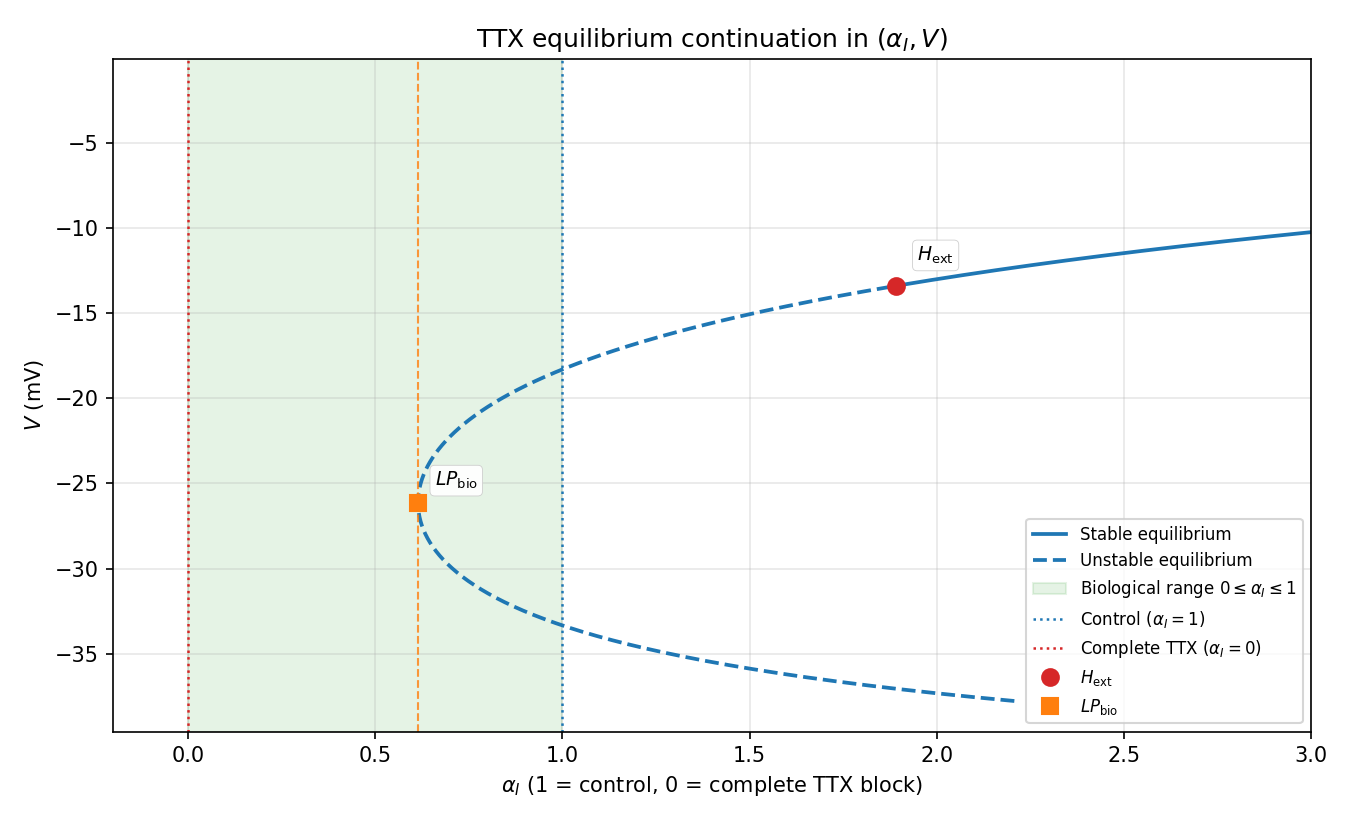


## 11. $\alpha_I$ limit-cycle continuation

LC-C is seeded from the unique exterior Hopf (`H_ext`, $\alpha_I\approx 1.89$), which is the same physical Hopf as $g_I\approx 7.57$ under scaling. It is **outside** the biological TTX interval and is retained for mathematical cross-checking only.


In [15]:
lc_a_results = {}

if not hopf_a_seed_map:
    print("No alpha_I Hopf points detected; skipping alpha_I LC-C.")
else:
    for report_lab, soft_lab in hopf_a_seed_map.items():
        hopf_row = next(r for r in specials_a if r["label"] == report_lab)
        bio = hopf_row.get("in_biological_01", False)
        cname = f"LC_a_{report_lab}"
        print(f"\n=== LC-C from EQ_alphaI:{soft_lab} as {cname} (biological={bio}) ===")
        try:
            PCLC = dst.args(name=cname, type="LC-C", force=True)
            PCLC.freepars = ["alpha_I"]
            PCLC.initpoint = f"EQ_alphaI:{soft_lab}"
            PCLC.MaxNumPoints = 300
            PCLC.StepSize = 1e-3
            PCLC.MaxStepSize = 0.05
            PCLC.MinStepSize = 1e-6
            PCLC.NumIntervals = 40
            PCLC.NumCollocation = 4
            PCLC.LocBifPoints = ["LPC"]
            PCLC.SaveEigen = True
            PCLC.verbosity = 0
            PC_a.newCurve(PCLC)
            t0 = dst.perf_counter()
            PC_a[cname].forward()
            sol_fwd = PC_a[cname].sol
            snap_fwd = lc_arrays(sol_fwd, "alpha_I")

            snap_bwd = None
            try:
                cname_b = f"{cname}_bwd_test"
                PCLCb = dst.args(name=cname_b, type="LC-C", force=True)
                PCLCb.freepars = ["alpha_I"]
                PCLCb.initpoint = f"EQ_alphaI:{soft_lab}"
                PCLCb.MaxNumPoints = 300
                PCLCb.StepSize = 1e-3
                PCLCb.MaxStepSize = 0.05
                PCLCb.MinStepSize = 1e-6
                PCLCb.NumIntervals = 40
                PCLCb.NumCollocation = 4
                PCLCb.LocBifPoints = ["LPC"]
                PCLCb.SaveEigen = True
                PCLCb.verbosity = 0
                PC_a.newCurve(PCLCb)
                PC_a[cname_b].backward()
                snap_bwd = lc_arrays(PC_a[cname_b].sol, "alpha_I")
            except Exception as exc:
                print("  backward-only test note:", type(exc).__name__, exc)

            same = branches_overlap(snap_fwd, snap_bwd) if snap_bwd is not None else True
            if same:
                print("  forward/backward: OVERLAP → retaining forward only.")
                sol_lc = sol_fwd
                direction_note = "forward_only_duplicate_backward"
            else:
                print("  forward/backward: complementary → using forward+backward combined sol.")
                try:
                    PC_a[cname].backward()
                except Exception:
                    pass
                sol_lc = PC_a[cname].sol
                direction_note = "merged_forward_backward"

            print(f"done in {dst.perf_counter()-t0:.3f}s; points={len(sol_lc)}")
            specs = collect_special_points(PC_a[cname], kinds=("LPC", "MX", "H"))
            vok, vnotes, vmeta = validate_lc_branch(
                sol_lc, "alpha_I", hopf_row["alpha_I"], hopf_row["V"], tag=report_lab
            )
            lc_a_results[report_lab] = {
                "curve": cname,
                "sol": sol_lc,
                "specials": specs,
                "ok": len(sol_lc) >= 2 and vok,
                "error": None,
                "biological": bio,
                "direction_note": direction_note,
                "forward_backward_duplicate": bool(same),
                "validation_notes": vnotes,
                "meta": vmeta,
                "hopf": hopf_row,
            }
        except Exception as exc:
            lc_a_results[report_lab] = {
                "curve": cname,
                "sol": None,
                "specials": [],
                "ok": False,
                "error": f"{type(exc).__name__}: {exc}",
                "biological": bio,
                "direction_note": None,
                "forward_backward_duplicate": None,
                "validation_notes": [],
                "meta": {},
                "hopf": hopf_row,
            }
            print("FAILED:", lc_a_results[report_lab]["error"])

# Report-quality alpha LC figure (no blank native overlay)
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_epc_report(
    ax,
    sol_a,
    "alpha_I",
    specials_a,
    title=r"$\alpha_I$ equilibria + exterior LC (mathematical)",
    xlabel=r"$\alpha_I$",
    shade_interval=(0.0, 1.0),
    vlines=[
        (1.0, r"control $\alpha_I=1$", "C0"),
        (0.0, r"complete block $\alpha_I=0$", "C3"),
    ],
)
for h, info in lc_a_results.items():
    if not info["ok"]:
        continue
    sol = info["sol"]
    a = np.asarray(sol["alpha_I"], dtype=float)
    ax.plot(a, sol["V_max"], color="C5", lw=1.6, label=rf"{h} $V_{{\max}}$ (exterior)")
    ax.plot(a, sol["V_min"], color="C5", lw=1.6, ls="--", label=rf"{h} $V_{{\min}}$ (exterior)")
ax.set_xlim(-0.2, 3.0)
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "05_ttx_alphaI_lcc.png", dpi=150)
plt.show()
plt.close(fig)
print("saved", FIGDIR / "05_ttx_alphaI_lcc.png")
if not any(info["ok"] for info in lc_a_results.values()):
    print("No successful alpha_I LC-C branches.")



=== LC-C from EQ_alphaI:H1 as LC_a_H_ext (biological=False) ===


running build


running config_cc


unifing config_cc, config, build_clib, build_ext, build commands --compiler options


running config_fc


unifing config_fc, config, build_clib, build_ext, build commands --fcompiler options


... (17 outputs left out)

 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    


   1   300  EP   2  2.584859E+00  2.031337E+01  1.563329E+01  9.727051E-01  9.746548E-01  6.559713E-01  9.999998E-01  1.087137E+02
 
  BR    PT  TY LAB    PAR(6)        L2-NORM       MAX(1)        MAX(2)        MAX(3)        MAX(4)        MAX(5)         PERIOD    


   1   300  EP   2  2.584859E+00  2.031337E+01  1.562938E+01  9.726982E-01  9.746639E-01  6.559631E-01  9.999998E-01  1.087137E+02
  forward/backward: OVERLAP → retaining forward only.
done in 2.197s; points=300
LC validation H_ext: ok=True; amplitude near Hopf ~ 0 mV; period range [78.01, 108.7] ms


saved /notebooks/outputs/figures/ttx_bifurcation/05_ttx_alphaI_lcc.png


**Figure — $\alpha_I$ exterior LC branch (mathematical cross-check).**

Limit-cycle envelope from the exterior Hopf ($H_{\mathrm{ext}}$, $\alpha_I\approx 1.89$), equivalent
under $g_I=4\alpha_I$ to the positive-$g_I$ LC family. Useful for validation; **not** part of
ordinary biological TTX blockade $\alpha_I:1\to 0$.

![$\alpha_I$ exterior LC branch (mathematical cross-check)](attachment:05_ttx_alphaI_lcc.png)


## 12. Cross-check: $g_I$ versus $\alpha_I$

### 12.1 Equilibrium special points

If the parameterisations are equivalent, bifurcations should match under $\alpha_I = g_I / g_I^{(0)}$ within continuation tolerance.

### 12.2 Positive-Hopf LC branch (critical)

The LC branch from $g_I\approx 7.567$ and the LC branch from $\alpha_I\approx 1.892$ should be the **same** periodic-orbit family after $g_I^{\mathrm{equiv}}=4\alpha_I$. We interpolate $V_{\min}$, $V_{\max}$, and period on the overlapping interval and report errors.


In [16]:
def match_points(g_rows, a_rows, kind, atol_alpha=0.05, atol_V=1.0):
    rows = []
    used = set()
    for gr in g_rows:
        if gr["type"] != kind or "g_I" not in gr:
            continue
        a_imp = gr["g_I"] / G_I0
        best = None
        best_score = 1e9
        for j, ar in enumerate(a_rows):
            if j in used or ar["type"] != kind or "alpha_I" not in ar:
                continue
            score = abs(a_imp - ar["alpha_I"]) + 0.02 * abs(gr.get("V", 0) - ar.get("V", 0))
            if score < best_score:
                best_score = score
                best = (j, ar)
        if best is None:
            continue
        j, ar = best
        agree = abs(a_imp - ar["alpha_I"]) <= atol_alpha and abs(gr.get("V", 0) - ar.get("V", 0)) <= atol_V
        used.add(j)
        rows.append(
            {
                "Point": f"{kind}:{gr['label']}~{ar['label']}",
                "g_I": gr["g_I"],
                "implied_alpha_I": a_imp,
                "direct_alpha_I": ar["alpha_I"],
                "V_gI": gr.get("V", float("nan")),
                "V_alpha": ar.get("V", float("nan")),
                "delta_alpha": a_imp - ar["alpha_I"],
                "delta_V": gr.get("V", float("nan")) - ar.get("V", float("nan")),
                "agreement": "yes" if agree else "check",
            }
        )
    return rows


cross = []
for kind in ("H", "LP"):
    cross.extend(match_points(specials_gI, specials_a, kind))

print("g_I vs alpha_I EP special-point cross-check:")
print(
    f"{'Point':28s} {'g_I':>10s} {'imp_a':>8s} {'dir_a':>8s} {'V_g':>10s} {'V_a':>10s} {'agree':>7s}"
)
for r in cross:
    print(
        f"{r['Point']:28s} {r['g_I']:10.4f} {r['implied_alpha_I']:8.4f} "
        f"{r['direct_alpha_I']:8.4f} {r['V_gI']:10.4f} {r['V_alpha']:10.4f} {r['agreement']:>7s}"
    )

if not cross:
    print("No overlapping special-point matches found (check branch coverage).")
else:
    bad = [r for r in cross if r["agreement"] != "yes"]
    if bad:
        print("WARNING: some matched points exceed tolerance.")
    else:
        print("EP special-point cross-check: PASS")

save_special_csv(DATADIR / "gI_alphaI_crosscheck.csv", cross)

# --- LC positive-Hopf cross-check ---
print("\n=== Positive-Hopf LC cross-check under g_I = 4 * alpha_I ===")
lc_cross_rows = []
lc_cross_ok = False
info_g = lc_results.get("H_pos")
info_a = None
for k, v in lc_a_results.items():
    if v.get("ok"):
        info_a = v
        info_a_key = k
        break

if not (info_g and info_g.get("ok") and info_a and info_a.get("ok")):
    print("SKIP / FAIL: need successful H_pos (g_I) and exterior alpha_I LC branches.")
    lc_cross_ok = False
else:
    pg, vmin_g, vmax_g, Tg = lc_arrays(info_g["sol"], "g_I")
    pa, vmin_a, vmax_a, Ta = lc_arrays(info_a["sol"], "alpha_I")
    g_from_a = 4.0 * pa

    lo = max(float(np.nanmin(pg)), float(np.nanmin(g_from_a)))
    hi = min(float(np.nanmax(pg)), float(np.nanmax(g_from_a)))
    print(f"Overlap g_I interval: [{lo:.6f}, {hi:.6f}]")
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        print("FAIL: no overlapping parameter interval.")
        lc_cross_ok = False
    else:
        grid = np.linspace(lo, hi, 80)

        def prep(x, *ys):
            order = np.argsort(x)
            x = np.asarray(x)[order]
            ys = [np.asarray(y)[order] for y in ys]
            xu, idx = np.unique(x, return_index=True)
            return (xu,) + tuple(y[idx] for y in ys)

        pg_s, vmin_gs, vmax_gs, Tg_s = prep(pg, vmin_g, vmax_g, Tg)
        ga_s, vmin_as, vmax_as, Ta_s = prep(g_from_a, vmin_a, vmax_a, Ta)

        vmin_gi = np.interp(grid, pg_s, vmin_gs)
        vmax_gi = np.interp(grid, pg_s, vmax_gs)
        T_gi = np.interp(grid, pg_s, Tg_s)
        vmin_ai = np.interp(grid, ga_s, vmin_as)
        vmax_ai = np.interp(grid, ga_s, vmax_as)
        T_ai = np.interp(grid, ga_s, Ta_s)

        d_vmin = np.abs(vmin_gi - vmin_ai)
        d_vmax = np.abs(vmax_gi - vmax_ai)
        d_T = np.abs(T_gi - T_ai)

        summary = {
            "overlap_gI_lo": lo,
            "overlap_gI_hi": hi,
            "max_abs_dVmin": float(np.nanmax(d_vmin)),
            "median_abs_dVmin": float(np.nanmedian(d_vmin)),
            "max_abs_dVmax": float(np.nanmax(d_vmax)),
            "median_abs_dVmax": float(np.nanmedian(d_vmax)),
            "max_abs_dT_ms": float(np.nanmax(d_T)),
            "median_abs_dT_ms": float(np.nanmedian(d_T)),
        }
        print("LC envelope/period errors on overlap:")
        for k, v in summary.items():
            print(f"  {k}: {v:.6g}")

        # Reasonable numerical continuation tolerance
        lc_cross_ok = (
            summary["max_abs_dVmin"] < 2.0
            and summary["max_abs_dVmax"] < 2.0
            and summary["max_abs_dT_ms"] < max(5.0, 0.05 * float(np.nanmedian(T_gi)))
        )
        print("LC cross-check:", "PASS" if lc_cross_ok else "FAIL — diagnose before trusting either LC branch")

        for i, gval in enumerate(grid):
            lc_cross_rows.append(
                {
                    "label": f"g={gval:.6f}",
                    "type": "LC_CMP",
                    "g_I": float(gval),
                    "Vmin_gI": float(vmin_gi[i]),
                    "Vmin_alpha": float(vmin_ai[i]),
                    "dVmin": float(d_vmin[i]),
                    "Vmax_gI": float(vmax_gi[i]),
                    "Vmax_alpha": float(vmax_ai[i]),
                    "dVmax": float(d_vmax[i]),
                    "T_gI_ms": float(T_gi[i]),
                    "T_alpha_ms": float(T_ai[i]),
                    "dT_ms": float(d_T[i]),
                }
            )
        lc_cross_rows.insert(
            0,
            {
                "label": "SUMMARY",
                "type": "SUMMARY",
                "agreement": "yes" if lc_cross_ok else "fail",
                **summary,
            },
        )

save_special_csv(DATADIR / "gI_alphaI_lcc_crosscheck.csv", lc_cross_rows)


g_I vs alpha_I EP special-point cross-check:
Point                               g_I    imp_a    dir_a        V_g        V_a   agree
H:H_pos~H_ext                    7.5681   1.8920   1.8920   -13.4078   -13.4078     yes
LP:LP_bio~LP_bio                 2.4566   0.6141   0.6141   -26.1342   -26.1342     yes
EP special-point cross-check: PASS
saved /notebooks/outputs/data/ttx_bifurcation/gI_alphaI_crosscheck.csv n= 2

=== Positive-Hopf LC cross-check under g_I = 4 * alpha_I ===
Overlap g_I interval: [7.568135, 10.339435]
LC envelope/period errors on overlap:
  overlap_gI_lo: 7.56813
  overlap_gI_hi: 10.3394
  max_abs_dVmin: 0.00261394
  median_abs_dVmin: 0.000507599
  max_abs_dVmax: 0.0104848
  median_abs_dVmax: 0.00148953
  max_abs_dT_ms: 0.00160107
  median_abs_dT_ms: 0.000153674
LC cross-check: PASS
saved /notebooks/outputs/data/ttx_bifurcation/gI_alphaI_lcc_crosscheck.csv n= 81


## 13. Biological interpretation

### A. Extended mathematical $g_I$ structure

Bounded $g_I$ EP-C recovers a folded equilibrium branch with:

- **two unique Hopf points** (`H_pos` near $g_I\approx 7.57$, `H_neg` near $g_I\approx -10.09$);
- **two unique limit points** (`LP_hi` near $g_I\approx 51.78$, `LP_bio` near $g_I\approx 2.46$).

In the corrected bounded run, raw `H1`/`H2` map to the two distinct Hopfs (`H_pos` near $g_I\approx 7.57$ and `H_neg` near $g_I\approx -10.09$). Deduplication remains in place in case a future longer run re-detects the same point twice under forward/backward continuation.

When validated, unique LC branches from `H_pos` and `H_neg` describe the local periodic-orbit structure. A large-period branch from `H_neg`, if retained, is reported only as large-period behaviour and is **not** labelled HOM/SNIC without further evidence.

### B. Biological $\alpha_I$ path from $1\to 0$

Along ordinary TTX blockade $\alpha_I\in[0,1]$:

- **no Hopf** is detected inside $[0,1]$;
- **one LP/fold** near $\alpha_I\approx 0.614$ ($g_I\approx 2.46$) lies on the path;
- the EP-C branch seeded at untreated $\alpha_I=1$ **terminates at this fold** and does not reach $\alpha_I=0$ on the same connected component.

Therefore the biologically relevant equilibrium transition identified by EP-C is a **saddle-node/fold of equilibria**, not a Hopf. This does **not** by itself prove a SNIC. Time-domain TTX simulations (notebooks 03–04) remain necessary to determine how bursting/spiking/slow-wave behaviour changes across this region.

The exterior Hopf near $\alpha_I\approx 1.89$ is the same physical Hopf as $g_I\approx 7.57$ and is useful for mathematical LC cross-checking only.

### Connection to the project hypothesis

Reducing the transient inward current under TTX is expected to suppress fast spiking and may produce slow-wave behaviour. EP-C/LC-C clarify local equilibrium and periodic structure; they do **not** by themselves prove the full bursting-to-slow-wave transition.


## 14. Numerical limitations / cautions

- Model time is **milliseconds**; AUTO `_T` is labelled in ms.
- $g_I$ continuation is intentionally bounded (~$[-60,220]$); values outside $[0,4]$ are non-physical for TTX.
- PyCont may leave `stab` unset; stability plots use $\max\mathrm{Re}(\lambda)$ when available.
- AUTO `LC-C` requires Docker; artefacts are written to the process CWD.
- `MX` means numerical termination, not a named bifurcation.
- Large periods near termination are suggestive only — not HOM/SNIC proofs.
- Raw special-point labels (`H1`, `LP1`, …) are software ordering; report labels use `H_pos` / `H_neg` / `LP_bio` / …
- Native PyDSTool LC `display` overlays can be blank/sparse for these coordinates; report figures use extracted $V_{\min}$/$V_{\max}$.
- Groupmate notebook outputs that used only `backward()` / shorter runs are not used as ground truth for the full 2H+2LP skeleton.


## 15. Summary and saved outputs


In [17]:
print("=== Summary ===")
print(f"g_I EP-C RAW: H={n_H_raw}, LP={n_LP_raw}")
print(f"g_I EP-C UNIQUE: H={n_H}, LP={n_LP}")
for row in specials_gI:
    print(
        f"  {row['label']}: g_I={row['g_I']:.6f}, alpha_I~={row['g_I']/G_I0:.6f}, "
        f"V={row['V']:.6f}, raw={row.get('raw_labels')}"
    )
print("g_I LC-C (unique seeds):")
for h, info in lc_results.items():
    meta = info.get("meta") or {}
    print(
        f"  {h}: ok={info['ok']} dup_fwd_bwd={info.get('forward_backward_duplicate')} "
        f"T∈[{meta.get('period_min', float('nan')):.4g}, {meta.get('period_max', float('nan')):.4g}] ms "
        f"err={info['error']}"
    )
print(f"alpha_I EP-C unique: {len(specials_a)}; bio H={len(bio_H)}, bio LP={len(bio_LP)}")
print("alpha_I LC-C:")
if not lc_a_results:
    print("  (none)")
for h, info in lc_a_results.items():
    print(
        f"  {h}: ok={info['ok']} biological={info.get('biological')} "
        f"dup_fwd_bwd={info.get('forward_backward_duplicate')} err={info['error']}"
    )
print("LC g_I↔alpha_I cross-check:", "PASS" if lc_cross_ok else "FAIL/SKIP")

print("\nFigures in", FIGDIR)
for p in sorted(FIGDIR.glob("05_ttx_*")):
    print(" ", p.name, p.stat().st_size, "bytes")
print("Data in", DATADIR)
for p in sorted(DATADIR.glob("*.csv")):
    print(" ", p.name)
print("\nNotebook 05 TTX bifurcation analysis complete.")


=== Summary ===
g_I EP-C RAW: H=2, LP=2
g_I EP-C UNIQUE: H=2, LP=2
  H_pos: g_I=7.568135, alpha_I~=1.892034, V=-13.407811, raw=['H1']
  H_neg: g_I=-10.090181, alpha_I~=-2.522545, V=-47.648494, raw=['H2']
  LP_bio: g_I=2.456555, alpha_I~=0.614139, V=-26.134221, raw=['LP2']
  LP_hi: g_I=51.784468, alpha_I~=12.946117, V=-45.326949, raw=['LP1']
g_I LC-C (unique seeds):
  H_pos: ok=True dup_fwd_bwd=True T∈[78.01, 143.1] ms err=None
  H_neg: ok=True dup_fwd_bwd=True T∈[7217, 1.083e+04] ms err=None
alpha_I EP-C unique: 2; bio H=0, bio LP=1
alpha_I LC-C:
  H_ext: ok=True biological=False dup_fwd_bwd=True err=None
LC g_I↔alpha_I cross-check: PASS

Figures in /notebooks/outputs/figures/ttx_bifurcation
  05_ttx_alphaI_epc.png 38789 bytes
  05_ttx_alphaI_epc_report.png 89125 bytes
  05_ttx_alphaI_lcc.png 95631 bytes
  05_ttx_gI_epc.png 44482 bytes
  05_ttx_gI_epc_report.png 76991 bytes
  05_ttx_gI_lcc.png 88941 bytes
  05_ttx_gI_lcc_report.png 102607 bytes
  05_ttx_gI_period.png 51462 bytes
  05_t